# BERTweet And Sparse Blend

Blends transformer and sparse-model probabilities with OOF-selected weights and thresholding. This is the conservative final-candidate workflow.

## Overview

- Combines BERTweet and sparse TF-IDF probabilities.
- Supports probability and rank-based blending.
- Searches blend weights using OOF F1.
- Writes `best_submission.csv` and `artifacts/best_metadata.json`.
- Includes diagnostics for the weight search, model agreement, and final score separation.

Source script: `blend_submission.py`


## Environment Setup

### Required Packages

Install the project dependencies from the repository root:

```bash
python3 -m venv .venv
.venv/bin/pip install -r requirements.txt
```

### Notebook Path

Run notebooks from the repository root when possible. If you open a notebook from `notebooks/`, the root-detection cell resolves the parent project directory automatically.

### Hardware Requirements

- CPU is sufficient for sparse, ensemble, and blend notebooks.
- A CUDA or Apple Silicon MPS GPU is recommended for BERTweet fine-tuning.
- 8 GB RAM is the minimum; 16 GB or more is recommended.


## What This Notebook Does

- Selects the final conservative blend from OOF performance.
- Avoids leaderboard-driven tuning and uses only supplied train labels.
- Produces `best_submission.csv` for submission review.


## Run Setup

Run notebooks from the repository root when possible. If you open a notebook from the `notebooks/` folder, the project-root detection cell below will still resolve the parent project directory.


In [1]:
from __future__ import annotations

# Optional setup for a fresh local runtime. Uncomment if dependencies are missing.
# %pip install -r requirements.txt
# %pip install -r ../requirements.txt

# Result summary: output for notebook cell 4
import importlib.util as _importlib_util
import pandas as _setup_pd
_setup_packages = ["pandas", "numpy", "scipy", "scikit-learn", "matplotlib", "seaborn"]
_setup_pd.DataFrame(
    {
        "package": _setup_packages,
        "available": [_importlib_util.find_spec(name.replace("scikit-learn", "sklearn")) is not None for name in _setup_packages],
    }
).set_index("package")


,available
package,
pandas,True
numpy,True
scipy,True
scikit-learn,True
matplotlib,True
seaborn,True


## Imports And Configuration


In [2]:
import argparse
import json
from pathlib import Path

import numpy as np
import pandas as pd
from scipy.stats import rankdata
from sklearn.metrics import f1_score, roc_auc_score


try:
    ROOT = Path(__file__).resolve().parent
except NameError:
    ROOT = Path.cwd()
    if not (ROOT / "data/train.csv").exists() and (ROOT.parent / "data/train.csv").exists():
        ROOT = ROOT.parent

# Result summary: output for notebook cell 6

pd.Series(
    {
        "project_root": str(ROOT),
        "train_file_exists": (ROOT / "data/train.csv").exists(),
        "test_file_exists": (ROOT / "data/test.csv").exists(),
        "bert_artifact_exists": (ROOT / "artifacts/bertweet_full/predictions.npz").exists(),
        "sparse_artifact_exists": (ROOT / "artifacts/sparse_3fold/predictions.npz").exists(),
    },
    name="runtime",
)


project_root              /Users/aftabhossain/Downloads/Competition
train_file_exists                                              True
test_file_exists                                               True
bert_artifact_exists                                           True
sparse_artifact_exists                                         True
Name: runtime, dtype: object

## Visualization Setup

The following cells use a shared plotting theme so exploratory charts, validation curves, and artifact diagnostics read consistently across the notebook series.


In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update(
    {
        "figure.dpi": 130,
        "savefig.dpi": 180,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.titleweight": "bold",
        "axes.titlesize": 12,
        "axes.labelsize": 10,
        "axes.edgecolor": "#d1d5db",
        "grid.color": "#e5e7eb",
        "legend.frameon": False,
    }
)

CLASS_COLORS = {
    "Not disaster": "#2563eb",
    "Disaster": "#dc2626",
    "Train": "#2563eb",
    "Test": "#059669",
}



In [4]:
def parse_args() -> argparse.Namespace:
    parser = argparse.ArgumentParser(description=__doc__)
    parser.add_argument(
        "--bert-predictions",
        type=Path,
        default=ROOT / "artifacts/bertweet_full/predictions.npz",
    )
    parser.add_argument(
        "--sparse-predictions",
        type=Path,
        default=ROOT / "artifacts/sparse_3fold/predictions.npz",
    )
    parser.add_argument("--train-path", type=Path, default=ROOT / "data/train.csv")
    parser.add_argument("--test-path", type=Path, default=ROOT / "data/test.csv")
    parser.add_argument("--output", type=Path, default=ROOT / "blended_submission.csv")
    parser.add_argument("--metadata", type=Path, default=ROOT / "artifacts/blend_metadata.json")
    parser.add_argument(
        "--score-mode",
        choices=("rank", "probability"),
        default="rank",
        help="Rank scores are safer when model probability calibration differs.",
    )
    return parser.parse_args(args=[])

# Result summary: output for notebook cell 9
_blend_args_preview = parse_args()
pd.DataFrame(
    {
        "setting": list(vars(_blend_args_preview)),
        "default": [str(value) for value in vars(_blend_args_preview).values()],
    }
)


,setting,default
0,bert_predictions,/Users/aftabhossain/Downloads/Competition/arti...
1,sparse_predictions,/Users/aftabhossain/Downloads/Competition/arti...
2,train_path,/Users/aftabhossain/Downloads/Competition/data...
3,test_path,/Users/aftabhossain/Downloads/Competition/data...
4,output,/Users/aftabhossain/Downloads/Competition/blen...
5,metadata,/Users/aftabhossain/Downloads/Competition/arti...
6,score_mode,rank


## Probability Utilities


In [5]:
def load_probability_pair(path: Path) -> tuple[np.ndarray, np.ndarray]:
    data = np.load(path)
    required = {"oof_probability", "test_probability"}
    if not required.issubset(data.files):
        raise ValueError(f"{path} must contain {sorted(required)}; found {data.files}")
    oof = np.asarray(data["oof_probability"], dtype=float)
    test = np.asarray(data["test_probability"], dtype=float)
    if np.isnan(oof).any() or np.isnan(test).any():
        raise ValueError(f"{path} contains incomplete predictions; finish all folds before blending.")
    return oof, test

# Result summary: output for notebook cell 11
_blend_demo_path = parse_args().bert_predictions
if _blend_demo_path.exists():
    _blend_demo_oof, _blend_demo_test = load_probability_pair(_blend_demo_path)
    pd.DataFrame(
        {
            "artifact": [str(_blend_demo_path)],
            "oof_rows": [len(_blend_demo_oof)],
            "test_rows": [len(_blend_demo_test)],
            "oof_mean": [_blend_demo_oof.mean()],
            "test_mean": [_blend_demo_test.mean()],
        }
    )
else:
    pd.DataFrame({"artifact_status": ["BERTweet probability artifact is not available yet."]})


In [6]:
def to_ranks(values: np.ndarray) -> np.ndarray:
    # Mid-ranks preserve ties and map the smallest/largest value into (0, 1).
    return rankdata(values, method="average") / (len(values) + 1.0)

# Result summary: output for notebook cell 12
_rank_demo = np.array([0.20, 0.90, 0.20, 0.50])
pd.DataFrame({"probability": _rank_demo, "rank_score": to_ranks(_rank_demo)})


,probability,rank_score
0,0.2,0.3
1,0.9,0.8
2,0.2,0.3
3,0.5,0.6


In [7]:
def best_f1(labels: np.ndarray, values: np.ndarray) -> tuple[float, float]:
    thresholds = np.arange(0.05, 0.951, 0.0025)
    f1s = np.asarray([f1_score(labels, values >= threshold) for threshold in thresholds])
    index = int(f1s.argmax())
    return float(f1s[index]), float(thresholds[index])

# Result summary: output for notebook cell 13
_blend_threshold_labels = np.array([0, 0, 1, 1])
_blend_threshold_values = np.array([0.10, 0.35, 0.60, 0.90])
_blend_score, _blend_threshold = best_f1(_blend_threshold_labels, _blend_threshold_values)
pd.DataFrame({"best_threshold": [_blend_threshold], "f1": [_blend_score]})


,best_threshold,f1
0,0.35,1.0


## Pipeline Entry Point


In [8]:
def main() -> None:
    args = parse_args()
    train = pd.read_csv(args.train_path)
    test = pd.read_csv(args.test_path)
    labels = train["target"].astype(int).to_numpy()
    bert_oof, bert_test = load_probability_pair(args.bert_predictions)
    sparse_oof, sparse_test = load_probability_pair(args.sparse_predictions)
    if not (len(labels) == len(bert_oof) == len(sparse_oof)):
        raise ValueError("OOF prediction lengths must match data/train.csv.")
    if not (len(test) == len(bert_test) == len(sparse_test)):
        raise ValueError("Test prediction lengths must match data/test.csv.")

    if args.score_mode == "rank":
        bert_oof_score, sparse_oof_score = to_ranks(bert_oof), to_ranks(sparse_oof)
        bert_test_score, sparse_test_score = to_ranks(bert_test), to_ranks(sparse_test)
    else:
        bert_oof_score, sparse_oof_score = bert_oof, sparse_oof
        bert_test_score, sparse_test_score = bert_test, sparse_test

    candidates: list[dict[str, float]] = []
    best: dict[str, float] | None = None
    for bert_weight in np.arange(0.50, 1.001, 0.025):
        oof_score = bert_weight * bert_oof_score + (1.0 - bert_weight) * sparse_oof_score
        f1, threshold = best_f1(labels, oof_score)
        candidate = {"bert_weight": float(bert_weight), "f1": f1, "threshold": threshold}
        candidates.append(candidate)
        if best is None or candidate["f1"] > best["f1"]:
            best = candidate
    assert best is not None

    final_score = best["bert_weight"] * bert_test_score + (1.0 - best["bert_weight"]) * sparse_test_score
    predictions = (final_score >= best["threshold"]).astype(int)
    args.output.parent.mkdir(parents=True, exist_ok=True)
    pd.DataFrame({"id": test["id"], "target": predictions}).to_csv(args.output, index=False)

    metadata = {
        "data_provenance": "OOF blend selection used only data/train.csv labels; no test targets or manual labels.",
        "score_mode": args.score_mode,
        "bert_oof_auc": float(roc_auc_score(labels, bert_oof)),
        "sparse_oof_auc": float(roc_auc_score(labels, sparse_oof)),
        "selected": best,
        "candidates": candidates,
        "test_positive_count": int(predictions.sum()),
        "test_positive_rate": float(predictions.mean()),
        "output": str(args.output),
    }
    args.metadata.parent.mkdir(parents=True, exist_ok=True)
    args.metadata.write_text(json.dumps(metadata, indent=2))
    print(
        f"Blend complete: OOF F1={best['f1']:.5f} threshold={best['threshold']:.3f} "
        f"BERT weight={best['bert_weight']:.3f} positives={predictions.sum()}/{len(predictions)} "
        f"output={args.output}",
        flush=True,
    )

# Result summary: output for notebook cell 15
pd.DataFrame(
    {
        "pipeline_stage": ["load", "score conversion", "OOF grid search", "write"],
        "result": ["BERTweet and sparse probabilities", "probability or rank scores", "selected weight and threshold", "blend submission and metadata"],
    }
)


,pipeline_stage,result
0,load,BERTweet and sparse probabilities
1,score conversion,probability or rank scores
2,OOF grid search,selected weight and threshold
3,write,blend submission and metadata


## Execute

Review the defaults in `parse_args()` first. Uncomment `main()` when you want the notebook to run the full pipeline and write artifacts.


In [9]:
# main()

# Result summary: output for notebook cell 17
_blend_preflight = pd.DataFrame(
    {
        "path": [ROOT / "data/train.csv", ROOT / "artifacts/bertweet_full/predictions.npz", ROOT / "artifacts/sparse_3fold/predictions.npz"],
    }
)
_blend_preflight["exists"] = _blend_preflight["path"].map(Path.exists)
_blend_preflight


,path,exists
0,/Users/aftabhossain/Downloads/Competition/data...,True
1,/Users/aftabhossain/Downloads/Competition/arti...,True
2,/Users/aftabhossain/Downloads/Competition/arti...,True


## Blend Visual Diagnostics

Run this after writing blend metadata and prediction artifacts. The plots show the weight search surface, model agreement, and final score distribution.


Selected BERTweet weight=0.825; OOF F1=0.81861; threshold=0.505; score mode=probability


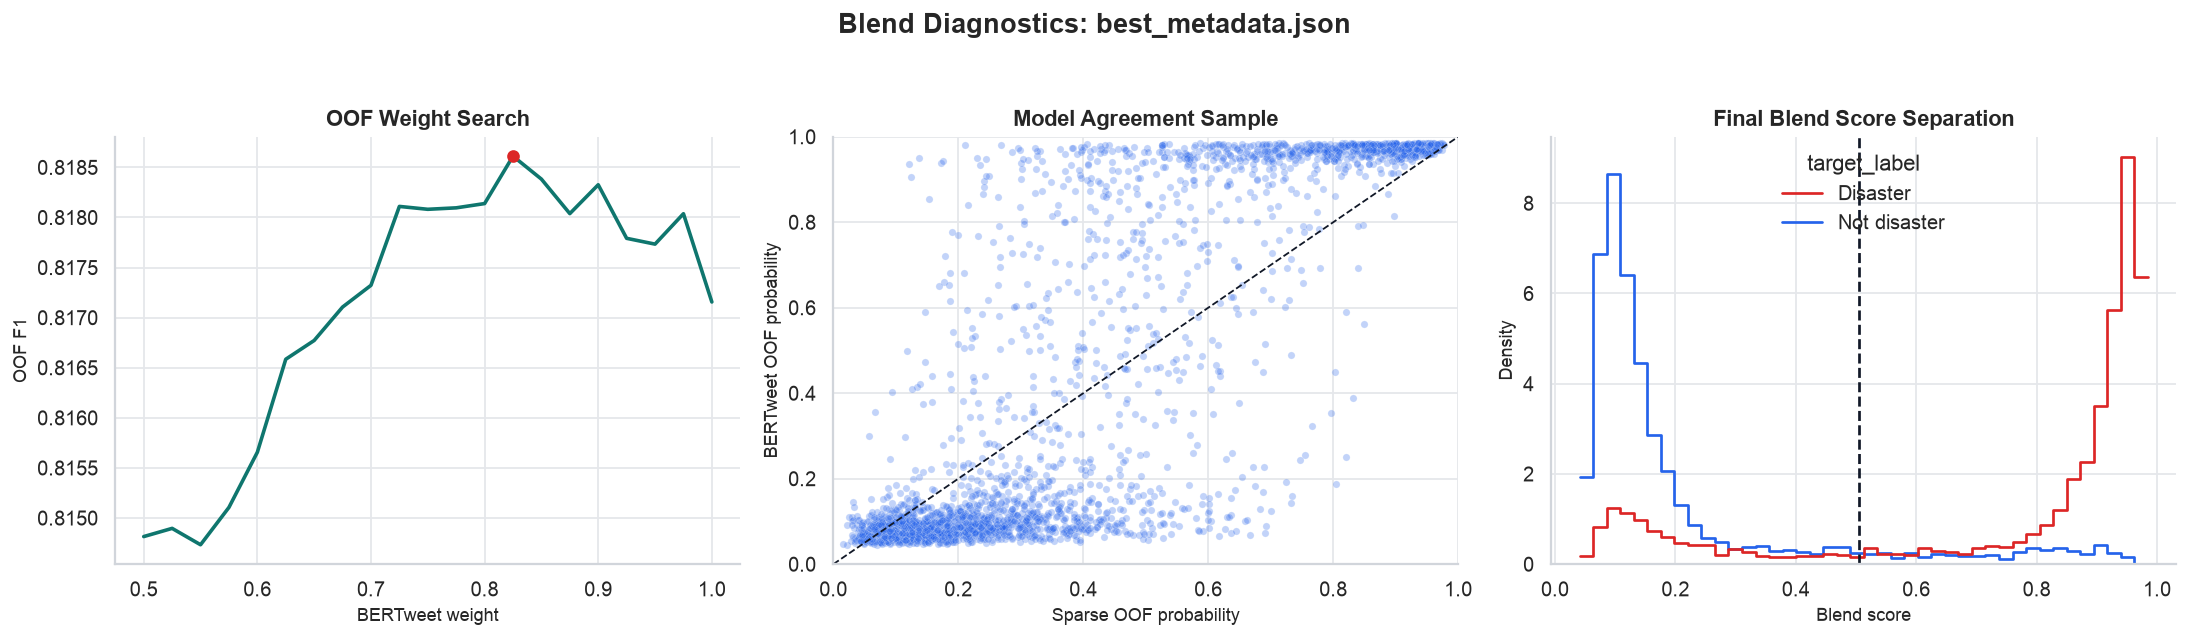

In [10]:
# Codex visualization block: blend diagnostics
train_labels = pd.read_csv(ROOT / "data/train.csv")["target"].astype(int).to_numpy()
metadata_candidates = [
    ROOT / "artifacts/best_metadata.json",
    ROOT / "artifacts/blend_probability_metadata.json",
    ROOT / "artifacts/blend_metadata.json",
]
bert_candidates = [
    ROOT / "artifacts/bertweet_ensemble_predictions.npz",
    ROOT / "artifacts/bertweet_full/predictions.npz",
]
sparse_candidates = [
    ROOT / "artifacts/sparse_3fold/predictions.npz",
    ROOT / "artifacts/sparse/predictions.npz",
]

metadata_path = next((path for path in metadata_candidates if path.exists()), None)

def _artifact_matching_auc(paths: list[Path], expected_auc: float | None) -> Path | None:
    available = [path for path in paths if path.exists()]
    if expected_auc is None:
        return available[0] if available else None
    for path in available:
        values = np.load(path)["oof_probability"]
        if len(values) == len(train_labels) and np.isclose(roc_auc_score(train_labels, values), expected_auc, atol=1e-6):
            return path
    return available[0] if available else None

if metadata_path is None:
    print("No blend metadata found yet. Run upstream models and this blend first, then rerun diagnostics.")
else:
    metadata = json.loads(metadata_path.read_text())
    bert_path = _artifact_matching_auc(bert_candidates, metadata.get("bert_oof_auc"))
    sparse_path = _artifact_matching_auc(sparse_candidates, metadata.get("sparse_oof_auc"))

    if bert_path is None or sparse_path is None:
        print("Missing BERTweet or sparse probability artifacts needed for blend diagnostics.")
    else:
        bert_values = np.load(bert_path)["oof_probability"]
        sparse_values = np.load(sparse_path)["oof_probability"]
        selected = metadata.get("selected", {})
        selected_weight = float(selected.get("bert_weight", 0.0))
        score_mode = metadata.get("score_mode", "probability")

        if score_mode == "rank":
            bert_scores = to_ranks(bert_values)
            sparse_scores = to_ranks(sparse_values)
        else:
            bert_scores = bert_values
            sparse_scores = sparse_values

        blend_values = selected_weight * bert_scores + (1.0 - selected_weight) * sparse_scores
        fallback_score, fallback_threshold = best_f1(train_labels, blend_values)
        selected_score = float(selected.get("f1", fallback_score))
        selected_threshold = float(selected.get("threshold", fallback_threshold))

        fig, axes = plt.subplots(1, 3, figsize=(17, 4.7))

        candidates = pd.DataFrame(metadata.get("candidates", []))
        if candidates.empty:
            axes[0].text(0.5, 0.5, "No candidate grid in metadata", ha="center", va="center")
            axes[0].set_axis_off()
        else:
            axes[0].plot(candidates["bert_weight"], candidates["f1"], color="#0f766e", linewidth=2)
            axes[0].scatter([selected_weight], [selected_score], color="#dc2626", zorder=3)
            axes[0].set_title("OOF Weight Search")
            axes[0].set_xlabel("BERTweet weight")
            axes[0].set_ylabel("OOF F1")

        agreement = pd.DataFrame({"BERTweet": bert_values, "Sparse": sparse_values})
        sns.scatterplot(
            data=agreement.sample(min(len(agreement), 2500), random_state=2027),
            x="Sparse",
            y="BERTweet",
            alpha=0.28,
            s=16,
            color="#2563eb",
            ax=axes[1],
        )
        axes[1].plot([0, 1], [0, 1], color="#111827", linestyle="--", linewidth=1)
        axes[1].set_title("Model Agreement Sample")
        axes[1].set_xlabel("Sparse OOF probability")
        axes[1].set_ylabel("BERTweet OOF probability")
        axes[1].set_xlim(0, 1)
        axes[1].set_ylim(0, 1)

        blend_frame = pd.DataFrame(
            {
                "score": blend_values,
                "target_label": np.where(train_labels == 1, "Disaster", "Not disaster"),
            }
        )
        sns.histplot(
            data=blend_frame,
            x="score",
            hue="target_label",
            bins=42,
            stat="density",
            common_norm=False,
            element="step",
            fill=False,
            palette={"Not disaster": CLASS_COLORS["Not disaster"], "Disaster": CLASS_COLORS["Disaster"]},
            ax=axes[2],
        )
        axes[2].axvline(selected_threshold, color="#111827", linestyle="--", linewidth=1.5)
        axes[2].set_title("Final Blend Score Separation")
        axes[2].set_xlabel("Blend score")
        axes[2].set_ylabel("Density")

        fig.suptitle(f"Blend Diagnostics: {metadata_path.name}", fontsize=15, fontweight="bold", y=1.04)
        plt.tight_layout()
        print(
            f"Selected BERTweet weight={selected_weight:.3f}; OOF F1={selected_score:.5f}; "
            f"threshold={selected_threshold:.3f}; score mode={score_mode}"
        )

